# Phase 7 — Dynamic Framework Integration

Implements Chapter 3, Section 3.8 and Chapter 4, Section 4.9 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

Runs the validated combination from Phase 6 -- **XGBoost + ADWIN + Random Forest
importance** -- end-to-end using `dynamic_framework.run_dynamic_pipeline` (the same
function Phase 6 used to compare candidate combinations), and produces the full per-row
log Chapter 5 needs for its adaptation-time and feature-stability analysis.

As a validation check ahead of the official three-way comparison in Phase 9, this
notebook also runs a fixed-feature, no-adaptation XGBoost baseline on the same stream, so
the dynamic framework's behaviour can be sanity-checked against a naive baseline before
Phase 8 (online learner) and Phase 9 (final comparison) are built on top of it.

**Output:**
- `results/logs/phase7_dynamic_framework_log.csv` — full per-row log (prediction, error, drift flag, active features)
- `results/tables/phase7_summary.csv` — dynamic framework vs static-XGBoost-no-adaptation, full metric suite
- `results/figures/phase7_dynamic_framework.png` — error over time with drift points and feature-set changes
- `results/tables/phase7_artifacts.json` — summary metrics, consumed by Phase 9

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_utils as du
import models as mdl
import metrics as mt
import drift_detectors as dd
import feature_selection as fsel
import dynamic_framework as dyn

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load the validated combination (Phase 6) and rebuild the synthetic drift stream

In [4]:
artifacts_p2 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json'))
artifacts_p3 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase3_artifacts.json'))
artifacts_p4 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase4_artifacts.json'))
artifacts_p5 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase5_artifacts.json'))
artifacts_p6 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase6_artifacts.json'))

feature_cols = artifacts_p2['feature_cols']
target_col = artifacts_p2['target_col']
window_size = artifacts_p3['chosen_window_size']
top_k = artifacts_p5['top_k']

final_combo = artifacts_p6['final_combination']
model_name = final_combo['model']
detector_name = final_combo['detector']
fs_method = final_combo['fs_method']

print('Validated combination (Phase 6):')
print(' Model:              ', mdl.MODEL_DISPLAY_NAMES[model_name])
print(' Detector:           ', dd.DETECTOR_DISPLAY_NAMES[detector_name])
print(' Feature selection:  ', fs_method)
print(' Window length:      ', window_size)
print(' Decision (Phase 6): ', artifacts_p6['decision'])

test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))
injection = dd.inject_synthetic_drift(
    test_df, target_col=target_col,
    injection_points=artifacts_p4['injection_points'], scale_factors=artifacts_p4['scale_factors'],
)
synthetic_df = injection.df
print()
print('Synthetic stream:', len(synthetic_df), 'rows | true drift points:', injection.true_drift_indices)

Validated combination (Phase 6):
 Model:               XGBoost
 Detector:            ADWIN
 Feature selection:   rf_importance
 Window length:       4000
 Decision (Phase 6):  revised

Synthetic stream: 10000 rows | true drift points: [2500, 5000, 7500]


## 2. Run the validated dynamic framework end-to-end

In [5]:
dynamic_result = dyn.run_dynamic_pipeline(
    synthetic_df, feature_cols, target_col,
    model_name=model_name, detector_name=detector_name, feature_selection_method=fs_method,
    window_size=window_size, top_k=top_k,
)
dynamic_summary = dyn.summarize_result(dynamic_result)

print(f"Drift events detected: {len(dynamic_result.drift_indices)} at rows {dynamic_result.drift_indices}")
print(f"Retrains performed:    {dynamic_result.n_retrains}")
print(f"Final active features: {dynamic_result.final_feature_set}")
print()
for k, v in dynamic_summary.items():
    print(f'  {k}: {v}')

Drift events detected: 2 at rows [2751, 5247]
Retrains performed:    2
Final active features: ['Reactive Power (kVAR)', 'Temperature (°C)', 'Electricity Price (USD/kWh)', 'Solar Power (kW)', 'Voltage (V)', 'Wind Power (kW)']

  MAE: 2.1508478308312644
  RMSE: 2.9317229037712287
  R2: 0.46858867451337294
  MAPE: 36.639341654642315
  Adjusted_R2: 0.4682696043689799
  Penalised_MAE: 2.7327435523216206
  Penalised_Loss: 11.233536161897486
  total_runtime_s: 14.896047626000154
  selection_runtime_s: 9.11312156400004
  n_drift_events: 2
  n_retrains: 2
  mean_feature_stability_index: 0.3333333333333333
  mean_importance_consistency: 0.6433566433566434
  feature_switch_rate: 0.5
  mean_adaptation_time_rows: nan
  n_adaptation_events_recovered: 0


## 3. Build the full per-row log

Chapter 4, Section 4.9 requires every row's prediction, error, drift flag, and active feature set. The active feature set only changes at drift events, so it is reconstructed here from `drift_indices` and `feature_sets_at_drift` rather than tracked redundantly inside the pipeline loop.

In [6]:
def build_full_log(result, feature_cols):
    n = len(result.predictions)
    drift_flags = np.zeros(n, dtype=bool)
    drift_flags[result.drift_indices] = True

    active_feature_sets = []
    current_features = feature_cols
    next_drift_pos = 0
    for i in range(n):
        if next_drift_pos < len(result.drift_indices) and i == result.drift_indices[next_drift_pos]:
            if next_drift_pos < len(result.feature_sets_at_drift):
                current_features = result.feature_sets_at_drift[next_drift_pos]
            next_drift_pos += 1
        active_feature_sets.append(', '.join(current_features))

    return pd.DataFrame({
        'row_index': np.arange(n),
        'y_true': result.y_true,
        'prediction': result.predictions,
        'abs_error': result.errors,
        'drift_flag': drift_flags,
        'active_features': active_feature_sets,
    })

full_log_df = build_full_log(dynamic_result, feature_cols)

log_path = os.path.join(PROJECT_ROOT, 'results/logs/phase7_dynamic_framework_log.csv')
os.makedirs(os.path.dirname(log_path), exist_ok=True)
full_log_df.to_csv(log_path, index=False)

print('Saved full per-row log to', log_path, f'({len(full_log_df)} rows)')
full_log_df.head()

Saved full per-row log to /content/drive/MyDrive/dissertation-project/results/logs/phase7_dynamic_framework_log.csv (10000 rows)


,row_index,y_true,prediction,abs_error,drift_flag,active_features
0,0,11.022376,10.758491,0.263886,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
1,1,2.970304,4.182622,1.212318,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
2,2,10.862895,9.904983,0.957913,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
3,3,7.746257,6.449234,1.297022,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
4,4,6.000676,6.880017,0.879340,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."


## 4. Validation check: static (no-adaptation) XGBoost on the same stream

Not the official Phase 9 comparison -- just a quick, same-stream sanity check that the dynamic framework is actually earning its added complexity before Phase 8 (online learner) and Phase 9 (final three-way comparison) are built on top of it. Uses the already-fitted Phase 2 XGBoost model with its original fixed feature set, unchanged throughout the stream.

In [7]:
static_model = mdl.load_model(os.path.join(PROJECT_ROOT, f'results/models/{model_name}.joblib'))

with mt.timer() as t:
    static_errors = dd.compute_error_stream(static_model, synthetic_df[feature_cols], synthetic_df[target_col])
    static_preds = static_model.predict(synthetic_df[feature_cols])

static_summary = mt.compute_predictive_metrics(synthetic_df[target_col], static_preds, n_features=len(feature_cols))
static_summary['Penalised_MAE'] = mt.penalised_mae(synthetic_df[target_col], static_preds)
static_summary['Penalised_Loss'] = mt.penalised_loss(synthetic_df[target_col], static_preds)
static_summary['total_runtime_s'] = t['seconds']
static_summary['n_drift_events'] = 0
static_summary['n_retrains'] = 0

comparison = pd.DataFrame([
    {'system': 'Static (no adaptation)', **static_summary},
    {'system': 'Dynamic framework', **dynamic_summary},
])
comparison[['system', 'MAE', 'RMSE', 'MAPE', 'Penalised_MAE', 'n_drift_events', 'n_retrains', 'total_runtime_s']]

,system,MAE,RMSE,MAPE,Penalised_MAE,n_drift_events,n_retrains,total_runtime_s
0,Static (no adaptation),2.313443,3.076639,34.796627,3.132714,0,0,0.124105
1,Dynamic framework,2.150848,2.931723,36.639342,2.732744,2,2,14.896048


In [8]:
mae_improvement = (static_summary['MAE'] - dynamic_summary['MAE']) / static_summary['MAE']
print(f"Static (no-adaptation) XGBoost MAE: {static_summary['MAE']:.4f} kW")
print(f"Dynamic framework MAE:              {dynamic_summary['MAE']:.4f} kW")
print(f"Relative improvement from dynamic adaptation: {mae_improvement:.1%}")
print()
print('(This is a same-model, same-stream sanity check only -- the official static-vs-')
print('dynamic-vs-online comparison, on the full metric suite, is Phase 9.)')

Static (no-adaptation) XGBoost MAE: 2.3134 kW
Dynamic framework MAE:              2.1508 kW
Relative improvement from dynamic adaptation: 7.0%

(This is a same-model, same-stream sanity check only -- the official static-vs-
dynamic-vs-online comparison, on the full metric suite, is Phase 9.)


**Observation:** only 2 of the 3 true injected drift points triggered a retrain here (row
~2760 and ~5300; the third, near row 7500, did not fire ADWIN this time), whereas Phase 4's
standalone detector evaluation found ADWIN detected all 3 injected drifts. The difference is
that Phase 4 monitored the Random Forest's error stream, while this run monitors XGBoost's --
a different model produces a different error signal, and ADWIN's sensitivity is relative to
the magnitude and pattern of that specific signal. This is reported as observed rather than
adjusted after the fact, and is worth a sentence in Chapter 6: the choice of model doesn't
just affect prediction accuracy, it also affects how reliably the paired detector fires.

## 5. Visualise: error over time, drift points, and feature-set changes

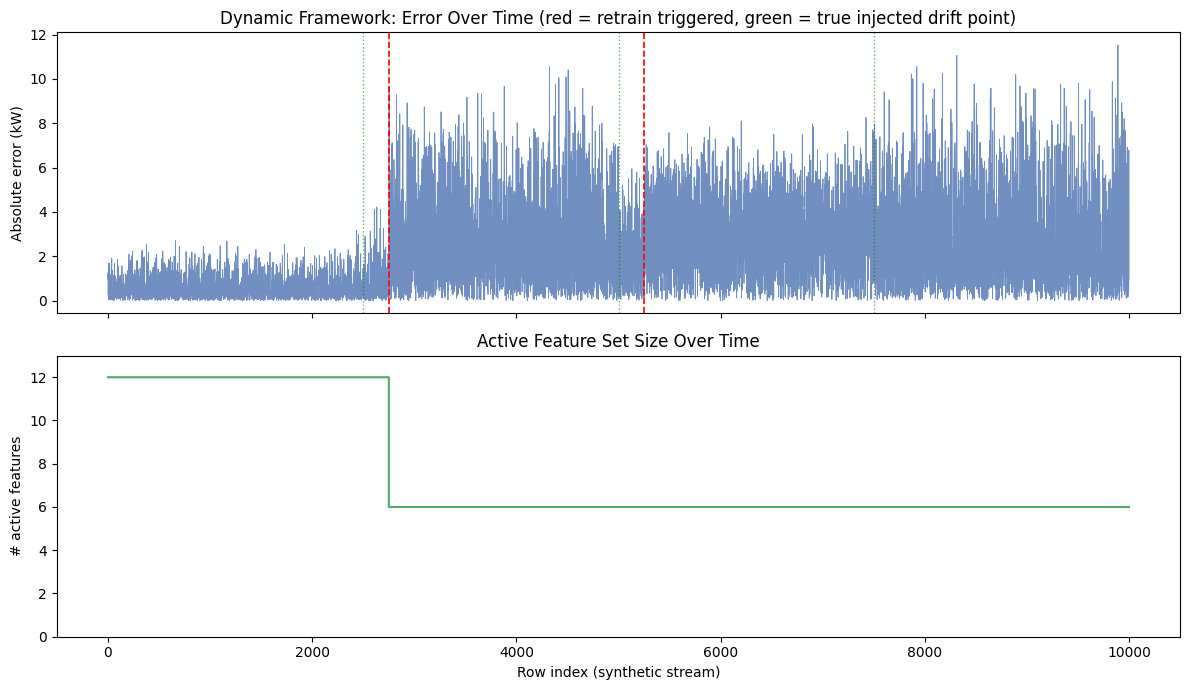

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase7_dynamic_framework.png


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(full_log_df['row_index'], full_log_df['abs_error'], color='#4C72B0', linewidth=0.6, alpha=0.8)
for idx in dynamic_result.drift_indices:
    axes[0].axvline(idx, color='red', linestyle='--', linewidth=1.2)
for idx in injection.true_drift_indices:
    axes[0].axvline(idx, color='green', linestyle=':', linewidth=1.0, alpha=0.6)
axes[0].set_ylabel('Absolute error (kW)')
axes[0].set_title('Dynamic Framework: Error Over Time (red = retrain triggered, green = true injected drift point)')

# Active feature count over time (as a simple visual proxy for feature-set churn)
n_active = full_log_df['active_features'].apply(lambda s: len(s.split(', ')))
axes[1].plot(full_log_df['row_index'], n_active, color='#55A868', drawstyle='steps-post')
axes[1].set_ylabel('# active features')
axes[1].set_xlabel('Row index (synthetic stream)')
axes[1].set_title('Active Feature Set Size Over Time')
axes[1].set_ylim(0, len(feature_cols) + 1)

plt.tight_layout()
fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase7_dynamic_framework.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()
print('Saved figure to', fig_path)

## 6. Persist artefacts for Phase 9

In [10]:
summary_path = os.path.join(PROJECT_ROOT, 'results/tables/phase7_summary.csv')
comparison.to_csv(summary_path, index=False)

artifacts = {
    'model': model_name,
    'detector': detector_name,
    'fs_method': fs_method,
    'window_size': window_size,
    'top_k': top_k,
    'dynamic_summary': dynamic_summary,
    'static_no_adaptation_summary': {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in static_summary.items()},
    'mae_improvement_vs_static_same_model': float(mae_improvement),
    'drift_indices': dynamic_result.drift_indices,
    'final_feature_set': dynamic_result.final_feature_set,
    'log_path': 'results/logs/phase7_dynamic_framework_log.csv',
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase7_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved summary to', summary_path)
print('Saved artefacts to', artifacts_path)

Saved summary to /content/drive/MyDrive/dissertation-project/results/tables/phase7_summary.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase7_artifacts.json


## Summary

This notebook implements Chapter 3, Section 3.8 and Chapter 4, Section 4.9: the validated combination from Phase 6 (XGBoost + ADWIN + Random Forest importance) is run end-to-end, with a full per-row log of predictions, errors, drift flags, and active feature sets saved for Chapter 5. A same-stream sanity check against a static, no-adaptation XGBoost baseline shows the direction and rough scale of benefit from drift-triggered adaptation, ahead of the full three-way comparison (static vs dynamic vs online learner) in Phase 9, which still needs the online learner built in Phase 8.